## Resources

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import seaborn as sns

ModuleNotFoundError: No module named 'numpy'

In [32]:

df = pd.read_csv('/content/student_performance_dataset.csv')

In [33]:
display(df.head())

,student_id,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade
0,1,Male,4.0,98.0,6.5,Bachelors,Yes,Yes,No,76.9,100.0,A
1,2,Female,6.3,100.0,5.7,High School,Yes,Yes,Yes,75.5,100.0,A
2,3,Male,4.9,85.3,7.9,Bachelors,Yes,No,Yes,88.5,97.3,A
3,4,Male,2.6,77.5,8.0,NaN,Yes,Yes,No,85.1,83.8,B
4,5,Male,2.2,89.6,4.6,Bachelors,Yes,No,Yes,61.8,68.3,D


In [34]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  1000 non-null   int64  
 1   gender                      1000 non-null   object 
 2   study_time_hours            1000 non-null   float64
 3   attendance_percent          1000 non-null   float64
 4   sleep_hours                 1000 non-null   float64
 5   parental_education          898 non-null    object 
 6   internet_access             1000 non-null   object 
 7   extracurricular_activities  1000 non-null   object 
 8   part_time_job               1000 non-null   object 
 9   previous_grade              1000 non-null   float64
 10  final_exam_score            1000 non-null   float64
 11  final_grade                 1000 non-null   object 
dtypes: float64(5), int64(1), object(6)
memory usage: 93.9+ KB
None


In [35]:
display(df.describe())

,student_id,study_time_hours,attendance_percent,sleep_hours,previous_grade,final_exam_score
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,3.570700,85.092300,6.799500,69.740900,83.543500
std,288.819436,1.478559,9.270685,1.203527,12.613425,10.341333
min,1.000000,0.500000,54.800000,3.200000,31.300000,46.800000
25%,250.750000,2.600000,78.800000,5.900000,61.000000,76.075000
50%,500.500000,3.600000,85.200000,6.800000,69.600000,83.800000
75%,750.250000,4.500000,91.900000,7.600000,78.400000,91.525000
max,1000.000000,8.100000,100.000000,10.000000,100.000000,100.000000


In [36]:
print('Missing values in each column:')
display(df.isnull().sum())

Missing values in each column:


,0
student_id,0
gender,0
study_time_hours,0
attendance_percent,0
sleep_hours,0
parental_education,102
internet_access,0
extracurricular_activities,0
part_time_job,0
previous_grade,0


In [37]:
mode_parental_education = df['parental_education'].mode()[0]
df['parental_education'].fillna(mode_parental_education, inplace=True)

print(f"Missing values in 'parental_education' filled with: {mode_parental_education}")
print('\nVerifying missing values after imputation:')
display(df.isnull().sum())

Missing values in 'parental_education' filled with: High School

Verifying missing values after imputation:


/tmp/ipykernel_2128/1182296237.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['parental_education'].fillna(mode_parental_education, inplace=True)


,0
student_id,0
gender,0
study_time_hours,0
attendance_percent,0
sleep_hours,0
parental_education,0
internet_access,0
extracurricular_activities,0
part_time_job,0
previous_grade,0


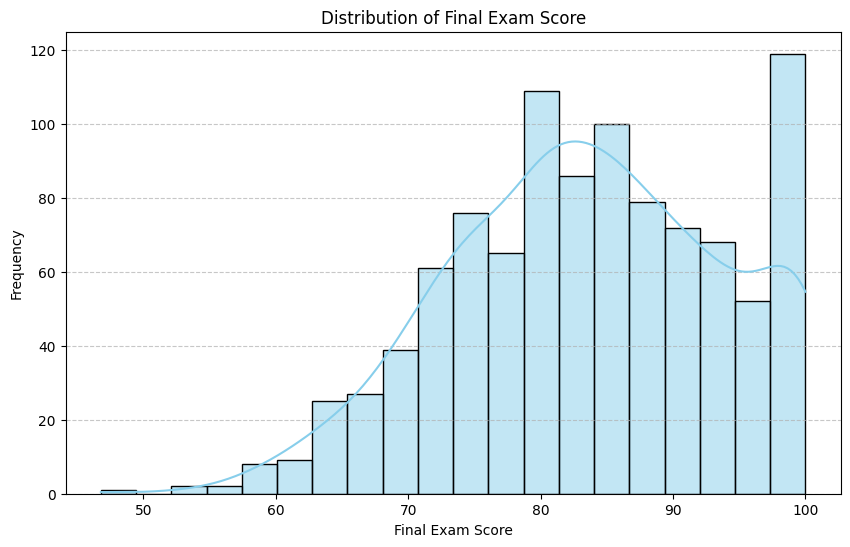

In [38]:
fig = plt.figure(figsize=(10, 6))
sns.histplot(df['final_exam_score'], kde=True, bins=20, color='skyblue')
plt.title('Distribution of Final Exam Score')
plt.xlabel('Final Exam Score')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

/tmp/ipykernel_2128/4230413822.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(['A', 'B', 'C', 'D', 'F'])


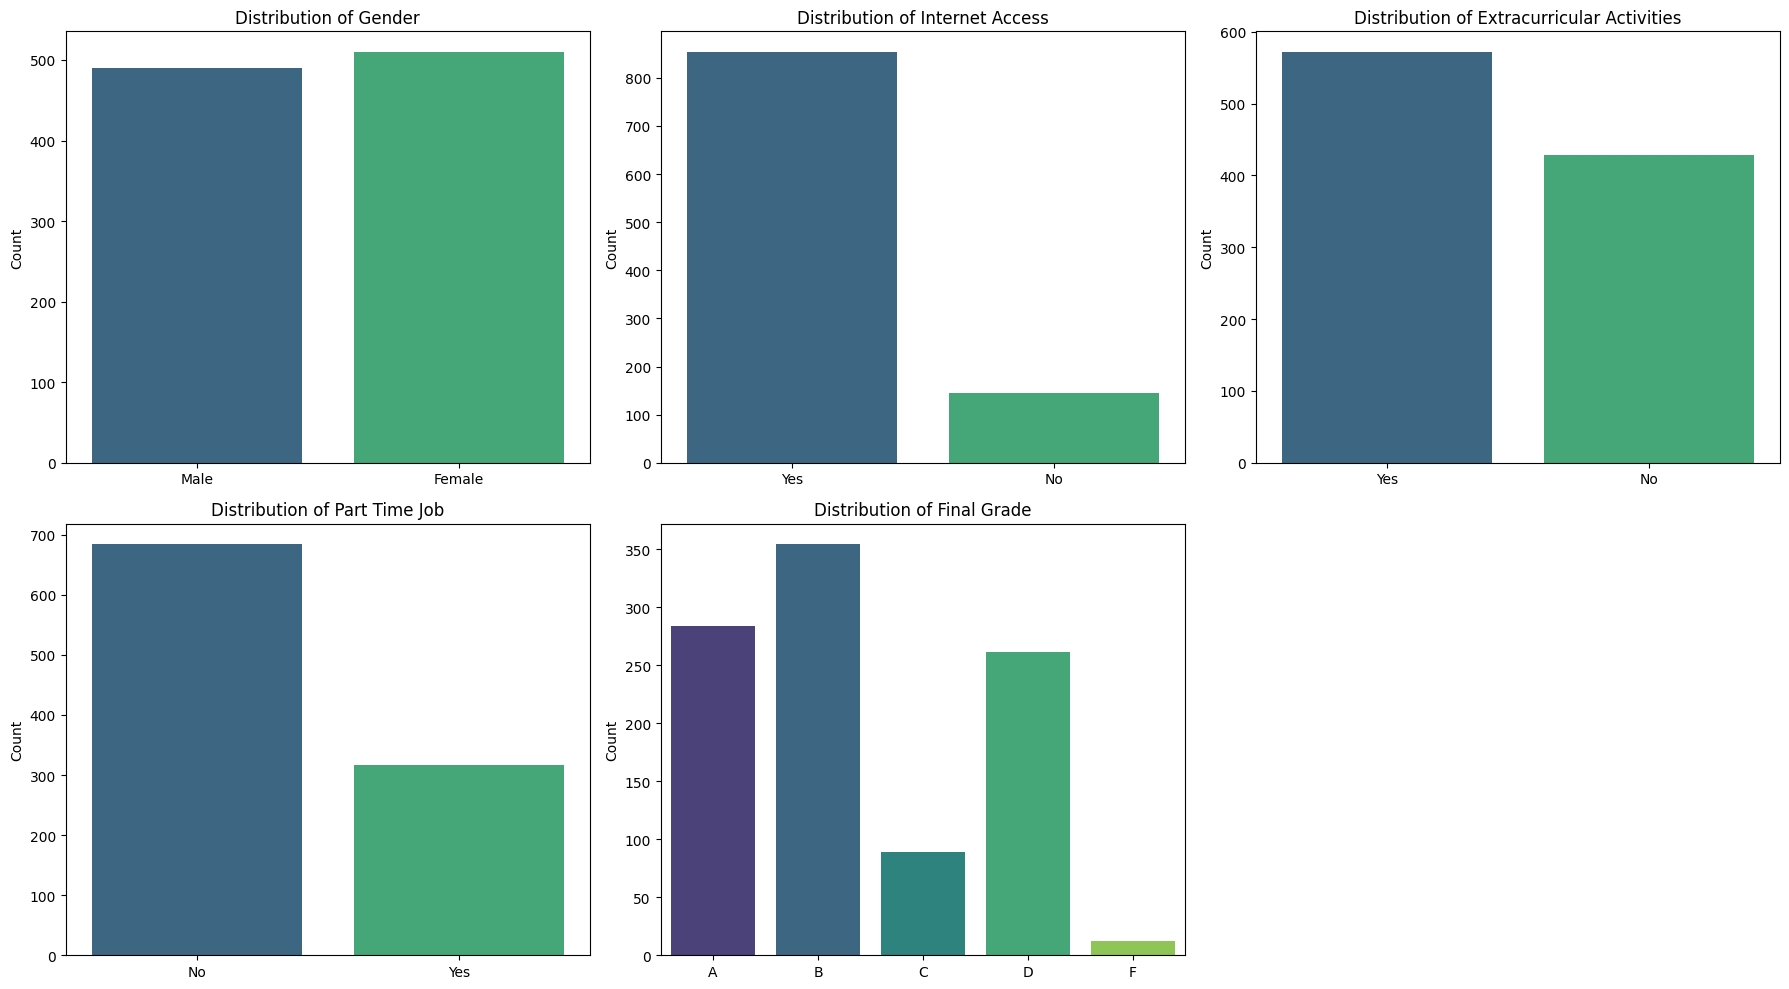

In [39]:
categorical_cols = ['gender', 'internet_access', 'extracurricular_activities', 'part_time_job', 'final_grade']

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    sns.countplot(x=col, data=df, ax=axes[i], palette='viridis', hue=col, legend=False)
    axes[i].set_title(f'Distribution of {col.replace("_", " ").title()}')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count')
    if col == 'final_grade':
        axes[i].set_xticklabels(['A', 'B', 'C', 'D', 'F'])

# Remove any unused subplots
for j in range(len(categorical_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

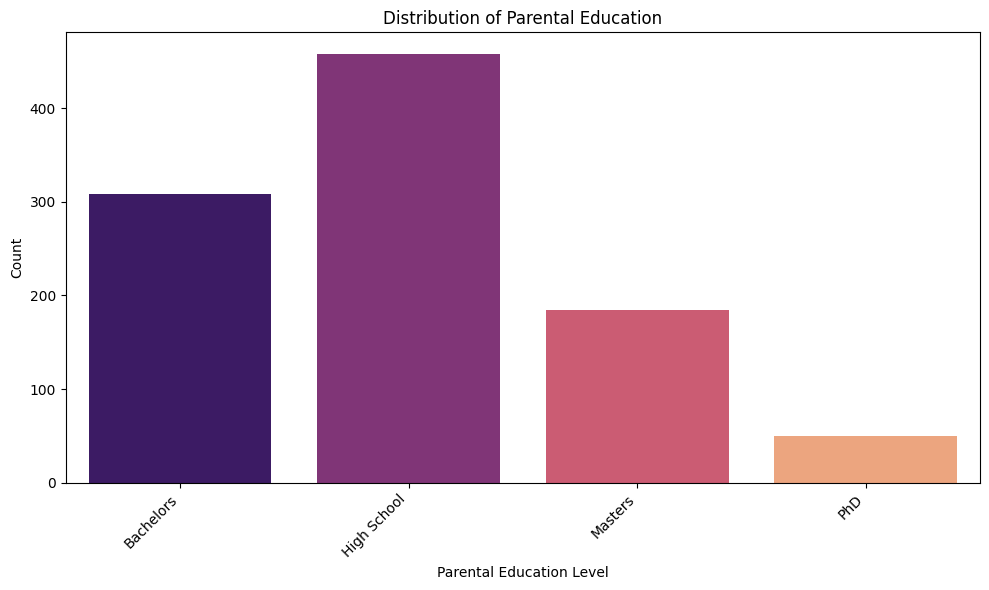

In [40]:
fig = plt.figure(figsize=(10, 6))
sns.countplot(x='parental_education', data=df, palette='magma', hue='parental_education', legend=False)
plt.title('Distribution of Parental Education')
plt.xlabel('Parental Education Level')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

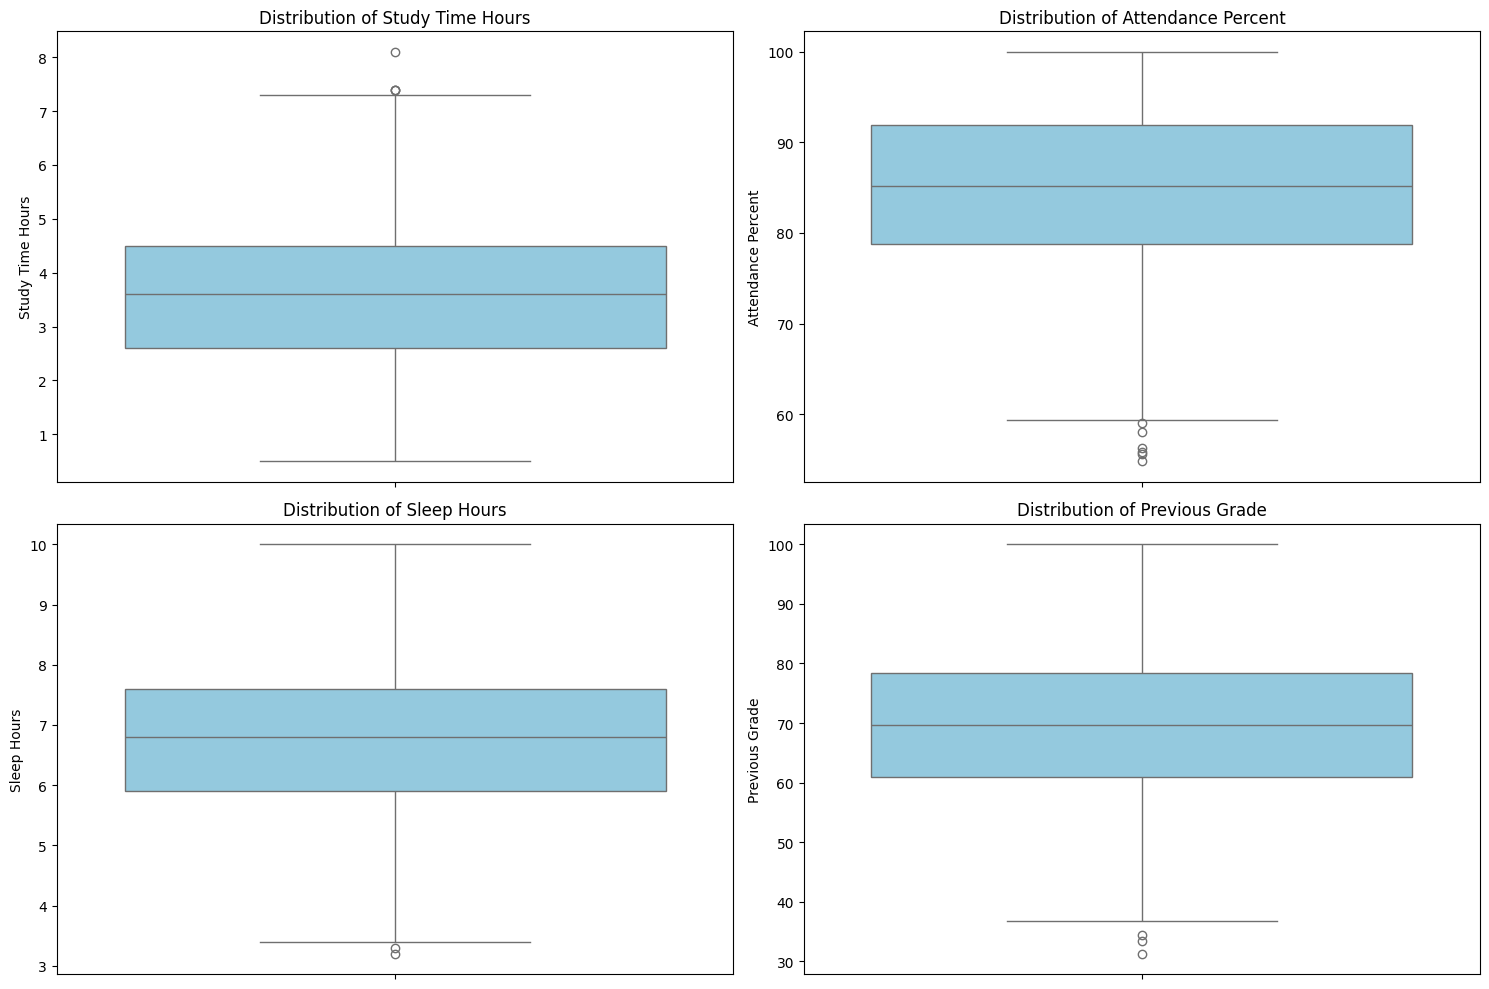

In [41]:
numerical_cols = ['study_time_hours', 'attendance_percent', 'sleep_hours', 'previous_grade']

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.boxplot(y=df[col], ax=axes[i], color='skyblue') # Changed palette to color
    axes[i].set_title(f'Distribution of {col.replace("_", " ").title()}')
    axes[i].set_ylabel(col.replace("_", " ").title())

plt.tight_layout()
plt.show()

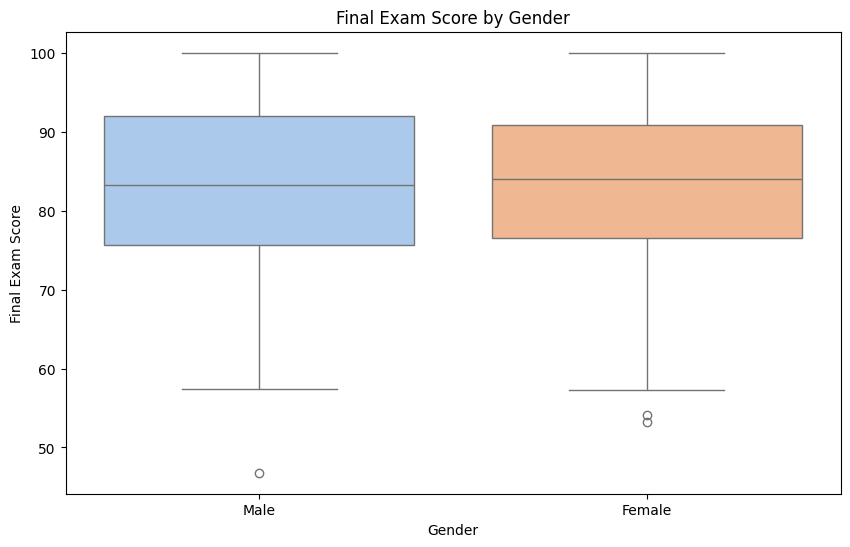

In [42]:
fig = plt.figure(figsize=(10, 6))
sns.boxplot(x='gender', y='final_exam_score', data=df, palette='pastel', hue='gender', legend=False)
plt.title('Final Exam Score by Gender')
plt.xlabel('Gender')
plt.ylabel('Final Exam Score')
plt.show()

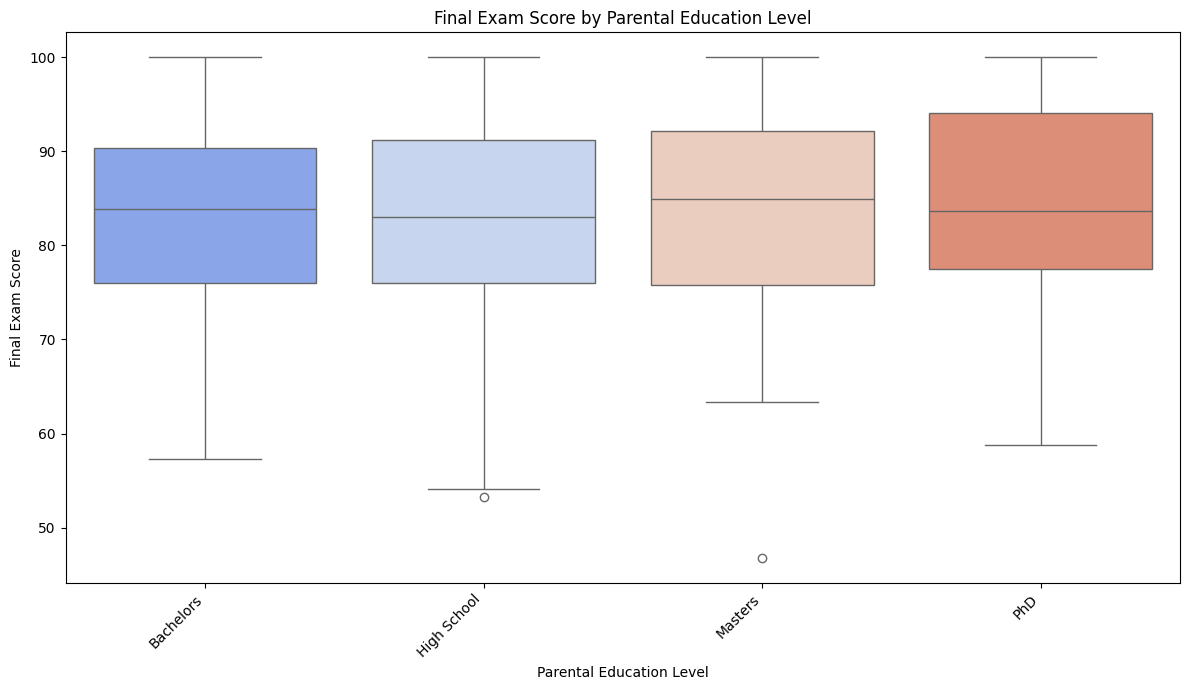

In [43]:
fig = plt.figure(figsize=(12, 7))
sns.boxplot(x='parental_education', y='final_exam_score', data=df, palette='coolwarm', hue='parental_education', legend=False)
plt.title('Final Exam Score by Parental Education Level')
plt.xlabel('Parental Education Level')
plt.ylabel('Final Exam Score')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

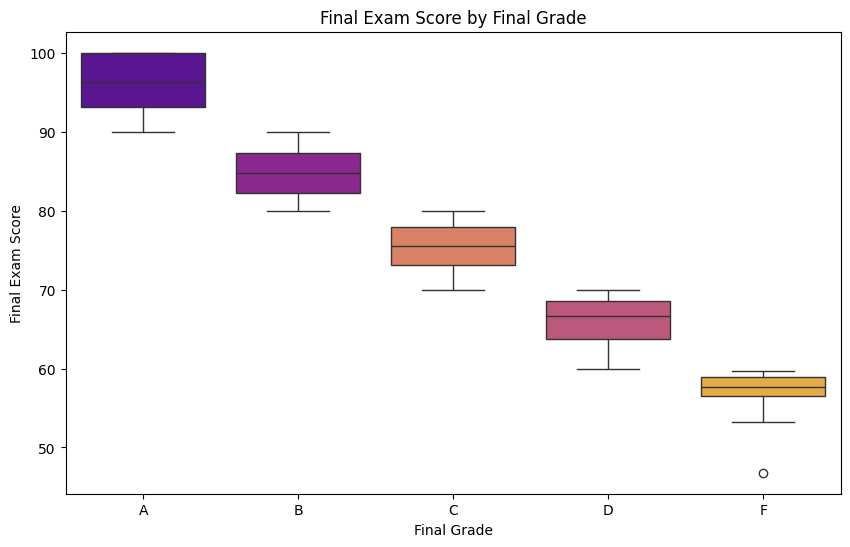

In [44]:
fig = plt.figure(figsize=(10, 6))
sns.boxplot(x='final_grade', y='final_exam_score', data=df, order=['A', 'B', 'C', 'D', 'F'], palette='plasma', hue='final_grade', legend=False)
plt.title('Final Exam Score by Final Grade')
plt.xlabel('Final Grade')
plt.ylabel('Final Exam Score')
plt.show()

In [45]:
# Define features (X) and target (y)
X = df.drop(['student_id', 'final_grade'], axis=1)
y = df['final_grade']

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

Features shape: (1000, 10)
Target shape: (1000,)


In [46]:
# Identify categorical columns for one-hot encoding
categorical_cols = X.select_dtypes(include=['object']).columns

# Apply one-hot encoding
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

display(X_encoded.head())

,study_time_hours,attendance_percent,sleep_hours,previous_grade,final_exam_score,gender_Male,parental_education_High School,parental_education_Masters,parental_education_PhD,internet_access_Yes,extracurricular_activities_Yes,part_time_job_Yes
0,4.0,98.0,6.5,76.9,100.0,True,False,False,False,True,True,False
1,6.3,100.0,5.7,75.5,100.0,False,True,False,False,True,True,True
2,4.9,85.3,7.9,88.5,97.3,True,False,False,False,True,False,True
3,2.6,77.5,8.0,85.1,83.8,True,True,False,False,True,True,False
4,2.2,89.6,4.6,61.8,68.3,True,False,False,False,True,False,True


In [51]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.3, random_state=42, stratify=y)

# Initialize StandardScaler
scaler = StandardScaler()

# Fit on training data and transform both training and testing data
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# For cross-validation, scale the entire X_encoded dataset (or apply scaler within CV pipeline)
X_encoded_scaled = scaler.fit_transform(X_encoded.copy())

print(f"X_train scaled shape: {X_train_scaled.shape}")
print(f"X_test scaled shape: {X_test_scaled.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

# Check the distribution of the target variable in train and test sets
print('\nTarget distribution in training set:')
display(y_train.value_counts(normalize=True))
print('\nTarget distribution in test set:')
display(y_test.value_counts(normalize=True))

X_train scaled shape: (700, 12)
X_test scaled shape: (300, 12)
y_train shape: (700,)
y_test shape: (300,)

Target distribution in training set:


,proportion
final_grade,
B,0.354286
A,0.284286
C,0.261429
D,0.088571
F,0.011429



Target distribution in test set:


,proportion
final_grade,
B,0.353333
A,0.283333
C,0.260000
D,0.090000
F,0.013333


In [48]:
from sklearn.model_selection import KFold

# Set up K-Fold Cross-Validation
n_splits = 5
kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

print(f"K-Fold Cross-Validation set up with {n_splits} splits.")
print(f"Number of splits: {kf.get_n_splits(X_encoded)}")

K-Fold Cross-Validation set up with 5 splits.
Number of splits: 5


In [52]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Initialize and train the Logistic Regression model
# We increase max_iter to ensure convergence for complex datasets
model = LogisticRegression(max_iter=1000, random_state=42)
# Use scaled training data
model.fit(X_train_scaled, y_train)

# Make predictions on the scaled test set
y_pred = model.predict(X_test_scaled)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print(f"Model: Logistic Regression")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision (weighted): {precision:.4f}")
print(f"Recall (weighted): {recall:.4f}")
print(f"F1-Score (weighted): {f1:.4f}")

Model: Logistic Regression
Accuracy: 0.9133
Precision (weighted): 0.9145
Recall (weighted): 0.9133
F1-Score (weighted): 0.9093


### K-Fold Cross-Validation for Logistic Regression

Now, we'll apply the K-Fold Cross-Validation strategy to our Logistic Regression model to get more robust performance metrics.

In [53]:
from sklearn.model_selection import cross_validate

# Perform cross-validation using the scaled entire dataset
cv_results = cross_validate(
    model, X_encoded_scaled, y,
    cv=kf,
    scoring=['accuracy', 'precision_weighted', 'recall_weighted', 'f1_weighted'],
    return_train_score=False # We are interested in test scores
)

print("K-Fold Cross-Validation Results for Logistic Regression (with scaled data):")
print(f"Average Accuracy: {cv_results['test_accuracy'].mean():.4f}")
print(f"Average Precision (weighted): {cv_results['test_precision_weighted'].mean():.4f}")
print(f"Average Recall (weighted): {cv_results['test_recall_weighted'].mean():.4f}")
print(f"Average F1-Score (weighted): {cv_results['test_f1_weighted'].mean():.4f}")

print("\nAll CV scores:")
for metric in cv_results:
    print(f"{metric}: {cv_results[metric]}")

K-Fold Cross-Validation Results for Logistic Regression (with scaled data):
Average Accuracy: 0.9160
Average Precision (weighted): 0.9104
Average Recall (weighted): 0.9160
Average F1-Score (weighted): 0.9106

All CV scores:
fit_time: [0.02546024 0.02041793 0.02323985 0.02603793 0.01987123]
score_time: [0.01392436 0.01354218 0.01444721 0.01305294 0.01348543]
test_accuracy: [0.895 0.895 0.925 0.94  0.925]
test_precision_weighted: [0.88681791 0.91032344 0.91241191 0.91644224 0.92607128]
test_recall_weighted: [0.895 0.895 0.925 0.94  0.925]
test_f1_weighted: [0.8881958  0.89496694 0.91705151 0.92755911 0.92527448]


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_

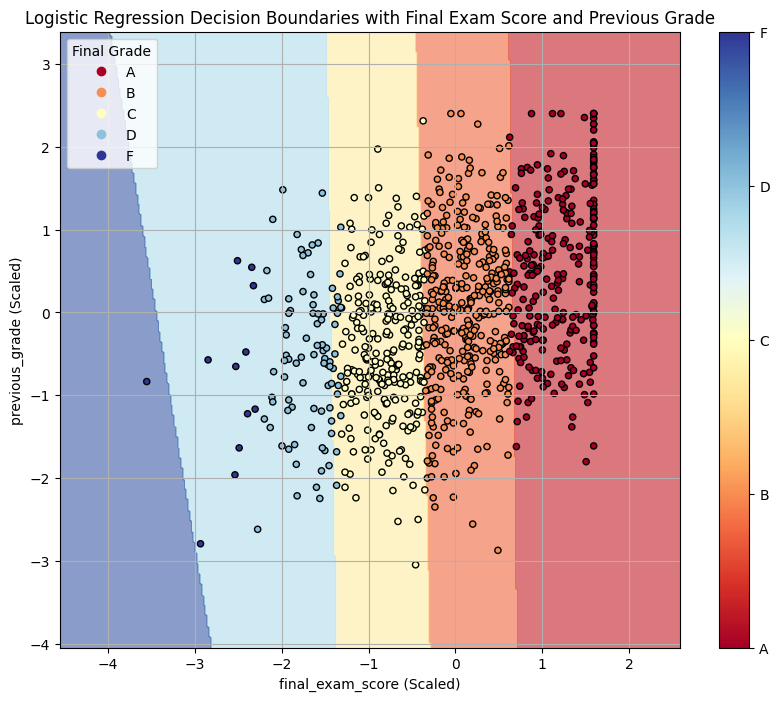

In [55]:
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
import numpy as np

# Select the two features for visualization from the scaled dataset
# Get the indices of 'final_exam_score' and 'previous_grade' from the original encoded columns
final_exam_score_idx = X_encoded.columns.get_loc('final_exam_score')
previous_grade_idx = X_encoded.columns.get_loc('previous_grade')

X_2d = X_encoded_scaled[:, [final_exam_score_idx, previous_grade_idx]]

# Train a Logistic Regression model on the 2D data
model_2d = LogisticRegression(max_iter=1000, random_state=42)
model_2d.fit(X_2d, y)

# Create a meshgrid to plot decision boundaries
x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
h = 0.02 # step size in the mesh
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

# Predict class for each point in the meshgrid
Z = model_2d.predict(np.c_[xx.ravel(), yy.ravel()])

# Map target labels to numerical values for contour plotting (e.g., A=0, B=1, etc.)
# Create a consistent mapping from original string labels to integers for all plots
unique_grades = np.sort(y.unique()) # Ensure consistent order
label_mapping = {label: i for i, label in enumerate(unique_grades)}
y_numeric = y.map(label_mapping)
Z_numeric = np.array([label_mapping[label] for label in Z])

# Put the result into a color plot
Z_numeric = Z_numeric.reshape(xx.shape)
plt.figure(figsize=(10, 8))
plt.contourf(xx, yy, Z_numeric, cmap=plt.cm.RdYlBu, alpha=0.6)

# Plot the data points
scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y_numeric, cmap=plt.cm.RdYlBu, edgecolor='k', s=20)
plt.xlabel(X_encoded.columns[final_exam_score_idx] + ' (Scaled)')
plt.ylabel(X_encoded.columns[previous_grade_idx] + ' (Scaled)')
plt.title('Logistic Regression Decision Boundaries with Final Exam Score and Previous Grade')

# Create a legend with original labels
handles, _ = scatter.legend_elements()
legend_labels = [label for label, i in sorted(label_mapping.items(), key=lambda item: item[1])]
plt.legend(handles=handles, labels=legend_labels, title='Final Grade')

# Add colorbar with correct ticks and labels
cbar = plt.colorbar(scatter, ticks=np.unique(y_numeric))
cbar.set_ticklabels(legend_labels)

plt.grid(True)
plt.show()

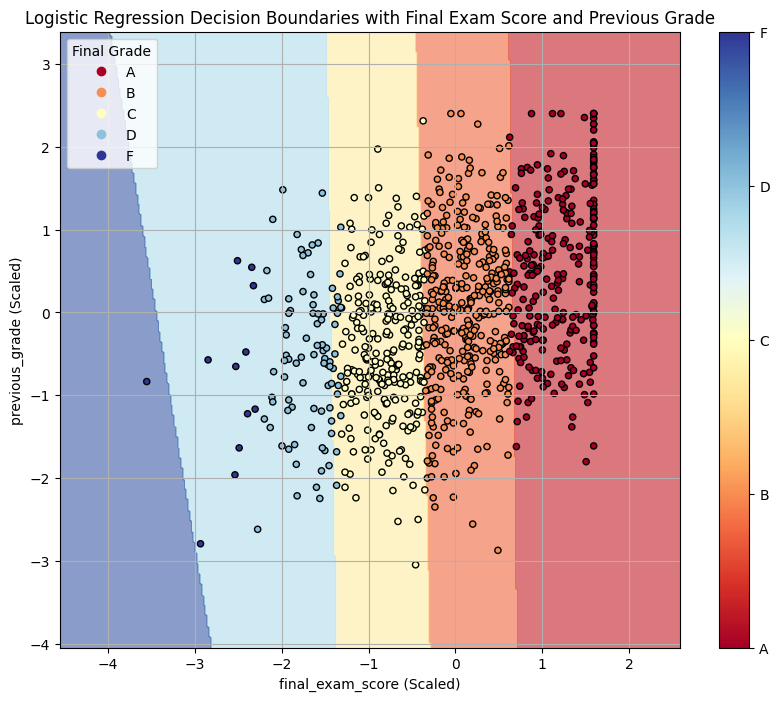

In [54]:
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
import numpy as np

# Select the two features for visualization from the scaled dataset
# Get the indices of 'final_exam_score' and 'previous_grade' from the original encoded columns
final_exam_score_idx = X_encoded.columns.get_loc('final_exam_score')
previous_grade_idx = X_encoded.columns.get_loc('previous_grade')

X_2d = X_encoded_scaled[:, [final_exam_score_idx, previous_grade_idx]]

# Train a Logistic Regression model on the 2D data
model_2d = LogisticRegression(max_iter=1000, random_state=42)
model_2d.fit(X_2d, y)

# Create a meshgrid to plot decision boundaries
x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
h = 0.02 # step size in the mesh
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

# Predict class for each point in the meshgrid
Z = model_2d.predict(np.c_[xx.ravel(), yy.ravel()])

# Map target labels to numerical values for contour plotting (e.g., A=0, B=1, etc.)
# Create a consistent mapping from original string labels to integers for all plots
unique_grades = np.sort(y.unique()) # Ensure consistent order
label_mapping = {label: i for i, label in enumerate(unique_grades)}
y_numeric = y.map(label_mapping)
Z_numeric = np.array([label_mapping[label] for label in Z])

# Put the result into a color plot
Z_numeric = Z_numeric.reshape(xx.shape)
plt.figure(figsize=(10, 8))
plt.contourf(xx, yy, Z_numeric, cmap=plt.cm.RdYlBu, alpha=0.6)

# Plot the data points
scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y_numeric, cmap=plt.cm.RdYlBu, edgecolor='k', s=20)
plt.xlabel(X_encoded.columns[final_exam_score_idx] + ' (Scaled)')
plt.ylabel(X_encoded.columns[previous_grade_idx] + ' (Scaled)')
plt.title('Logistic Regression Decision Boundaries with Final Exam Score and Previous Grade')

# Create a legend with original labels
handles, _ = scatter.legend_elements()
legend_labels = [label for label, i in sorted(label_mapping.items(), key=lambda item: item[1])]
plt.legend(handles=handles, labels=legend_labels, title='Final Grade')

# Add colorbar with correct ticks and labels
cbar = plt.colorbar(scatter, ticks=np.unique(y_numeric))
cbar.set_ticklabels(legend_labels)

plt.grid(True)
plt.show()

### Confusion Matrix Analysis

To further evaluate the model's performance on the test set, especially for multi-class classification, we will generate and visualize a confusion matrix. This matrix provides a detailed breakdown of correct and incorrect predictions for each class.

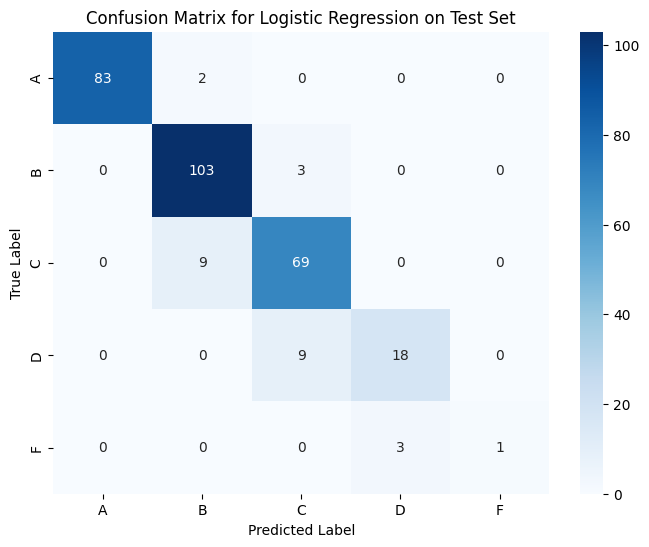

In [56]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=np.sort(y.unique())) # Ensure consistent order of labels

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=np.sort(y.unique()), yticklabels=np.sort(y.unique()))
plt.title('Confusion Matrix for Logistic Regression on Test Set')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()